# Weighted Ensemble Evaluation

This notebook allows you to:
1. Load OOF predictions from different models
2. Apply custom weights to each model
3. Evaluate performance using standard metrics from MODEL_TRACKING.md
4. Find optimal weight combinations

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, roc_auc_score, log_loss, matthews_corrcoef,
    confusion_matrix, classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize
import json
from datetime import datetime

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 4)

print("Libraries imported successfully!")

Libraries imported successfully!


## Load OOF Predictions

In [2]:
# Load the OOF predictions
oof_df = pd.read_csv('oof_predictions.csv')

print("OOF Predictions loaded successfully!")
print(f"Shape: {oof_df.shape}")
print(f"\nColumns: {list(oof_df.columns)}")
print(f"\nFirst few rows:")
oof_df.head(10)

OOF Predictions loaded successfully!
Shape: (4212, 7)

Columns: ['id', 'label', 'hybrid_charcnn_mlp', 'xgboost_optuna', 'ridge', 'deberta', 'simple_average']

First few rows:


,id,label,hybrid_charcnn_mlp,xgboost_optuna,ridge,deberta,simple_average
0,0,0,5.6650e-09,1.7513e-05,0.2484,0.0004,0.0622
1,1,0,1.0531e-06,7.3621e-05,0.2290,0.0004,0.0574
2,2,1,9.2460e-01,9.5980e-01,0.5075,0.9992,0.8478
3,3,0,8.8368e-04,1.6888e-04,0.3058,0.0003,0.0768
4,4,0,2.3708e-05,1.4218e-03,0.2803,0.0004,0.0705
5,5,0,2.9782e-01,1.3854e-02,0.3650,0.0005,0.1693
6,6,1,3.3028e-01,1.2997e-01,0.4678,0.9995,0.4819
7,7,0,1.0904e-06,2.5455e-04,0.3001,0.0003,0.0752
8,8,1,1.9774e-01,7.4259e-01,0.4874,0.9973,0.6063
9,9,1,9.9994e-01,9.9925e-01,0.7911,0.9995,0.9475


In [3]:
# Get model names (exclude 'id', 'label', and 'simple_average')
model_columns = [col for col in oof_df.columns if col not in ['id', 'label', 'simple_average']]

print(f"Available models: {model_columns}")
print(f"Number of models: {len(model_columns)}")
print(f"\nTrue labels distribution:")
print(oof_df['label'].value_counts())

Available models: ['hybrid_charcnn_mlp', 'xgboost_optuna', 'ridge', 'deberta']
Number of models: 4

True labels distribution:
label
0    2733
1    1479
Name: count, dtype: int64


## Evaluation Functions (Based on MODEL_TRACKING.md)

In [4]:
def calculate_metrics(y_true, y_pred_proba, threshold=0.5):
    """
    Calculate all standard metrics from MODEL_TRACKING.md
    
    Args:
        y_true: True labels
        y_pred_proba: Predicted probabilities
        threshold: Classification threshold (default 0.5)
    
    Returns:
        Dictionary with all metrics
    """
    y_pred = (y_pred_proba >= threshold).astype(int)
    
    metrics = {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'roc_auc': roc_auc_score(y_true, y_pred_proba),
        'log_loss': log_loss(y_true, y_pred_proba),
        'mcc': matthews_corrcoef(y_true, y_pred)
    }
    
    # Specificity (True Negative Rate)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    metrics['specificity'] = tn / (tn + fp) if (tn + fp) > 0 else 0
    
    return metrics

def print_metrics(metrics, title="Metrics"):
    """Pretty print metrics"""
    print(f"\n{'='*60}")
    print(f"{title:^60}")
    print(f"{'='*60}")
    print(f"Accuracy:       {metrics['accuracy']:.4f}")
    print(f"Precision:      {metrics['precision']:.4f}")
    print(f"Recall:         {metrics['recall']:.4f}")
    print(f"F1 Score:       {metrics['f1']:.4f}")
    print(f"ROC AUC:        {metrics['roc_auc']:.4f} * (Primary Metric)")
    print(f"Log Loss:       {metrics['log_loss']:.4f}")
    print(f"MCC:            {metrics['mcc']:.4f}")
    print(f"Specificity:    {metrics['specificity']:.4f}")
    print(f"{'='*60}\n")

print("Evaluation functions defined!")

Evaluation functions defined!


## Evaluate Individual Models

In [5]:
# Evaluate each individual model
individual_results = []

for model_name in model_columns:
    metrics = calculate_metrics(oof_df['label'], oof_df[model_name])
    metrics['model'] = model_name
    individual_results.append(metrics)
    print_metrics(metrics, f"Model: {model_name}")

# Create comparison dataframe
comparison_df = pd.DataFrame(individual_results)
comparison_df = comparison_df.sort_values('roc_auc', ascending=False)
comparison_df


                 Model: hybrid_charcnn_mlp                  
Accuracy:       0.9677
Precision:      0.9546
Recall:         0.9533
F1 Score:       0.9540
ROC AUC:        0.9954 * (Primary Metric)
Log Loss:       0.0826
MCC:            0.9291
Specificity:    0.9755


                   Model: xgboost_optuna                    
Accuracy:       0.9625
Precision:      0.9584
Recall:         0.9337
F1 Score:       0.9459
ROC AUC:        0.9927 * (Primary Metric)
Log Loss:       0.1056
MCC:            0.9174
Specificity:    0.9780


                        Model: ridge                        
Accuracy:       0.9701
Precision:      0.9761
Recall:         0.9378
F1 Score:       0.9566
ROC AUC:        0.9965 * (Primary Metric)
Log Loss:       0.4008
MCC:            0.9342
Specificity:    0.9876


                       Model: deberta                       
Accuracy:       0.9846
Precision:      0.9664
Recall:         0.9905
F1 Score:       0.9783
ROC AUC:        0.9987 * (Primary Metric)
Log Lo

,accuracy,precision,recall,f1,roc_auc,log_loss,mcc,specificity,model
3,0.9846,0.9664,0.9905,0.9783,0.9987,0.0712,0.9665,0.9813,deberta
2,0.9701,0.9761,0.9378,0.9566,0.9965,0.4008,0.9342,0.9876,ridge
0,0.9677,0.9546,0.9533,0.9540,0.9954,0.0826,0.9291,0.9755,hybrid_charcnn_mlp
1,0.9625,0.9584,0.9337,0.9459,0.9927,0.1056,0.9174,0.9780,xgboost_optuna


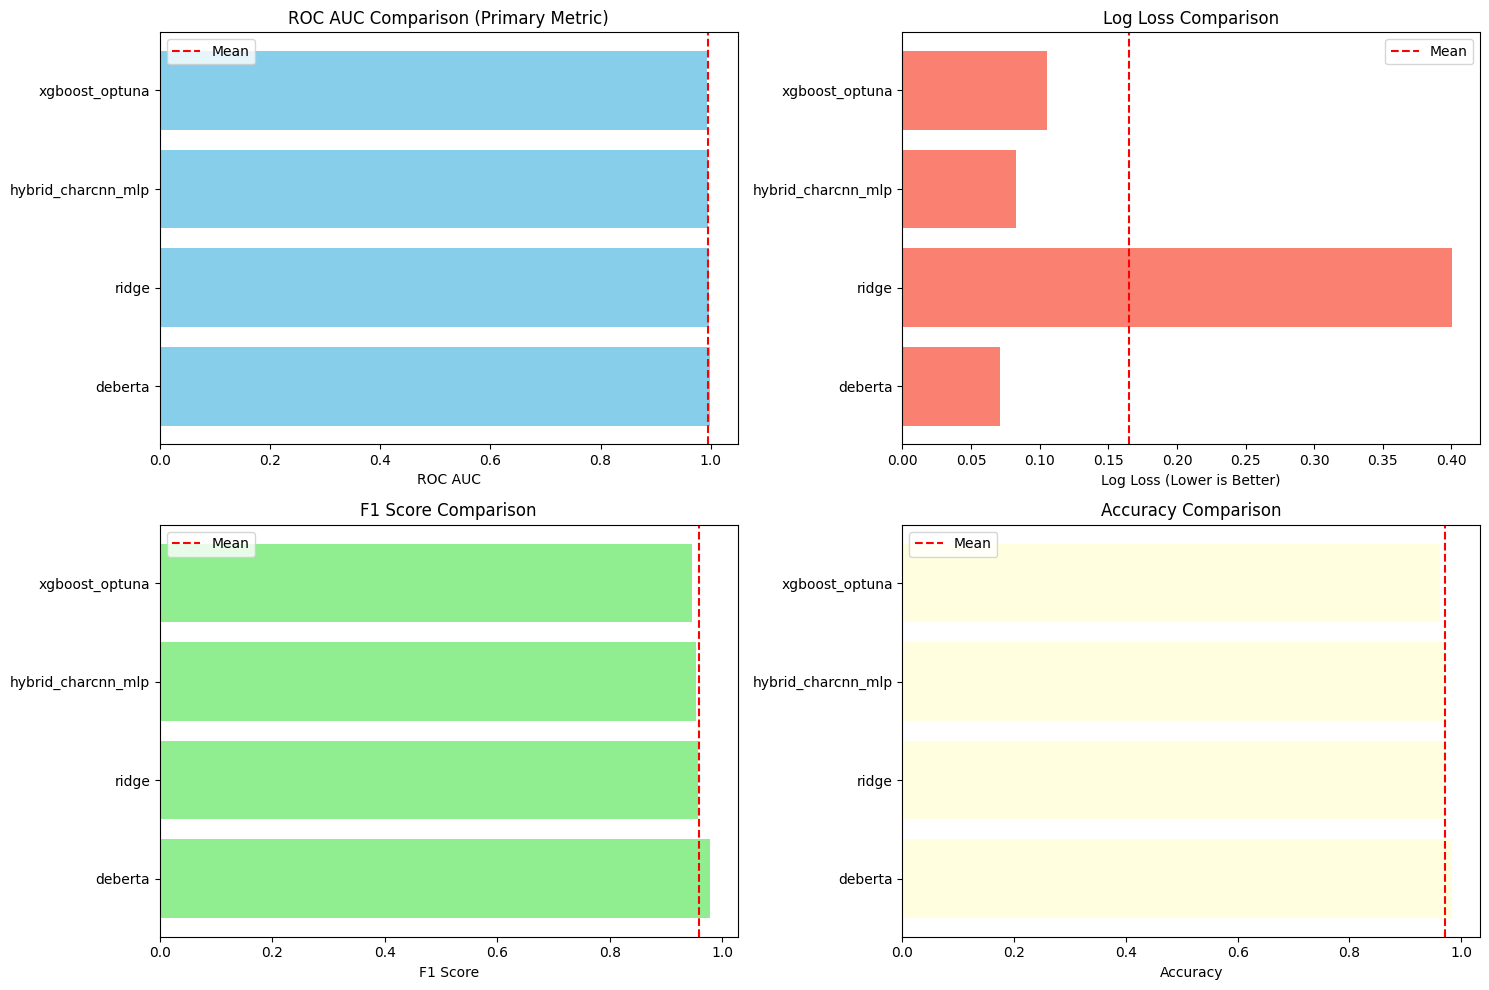

In [6]:
# Visualize model comparison
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# ROC AUC
axes[0, 0].barh(comparison_df['model'], comparison_df['roc_auc'], color='skyblue')
axes[0, 0].set_xlabel('ROC AUC')
axes[0, 0].set_title('ROC AUC Comparison (Primary Metric)')
axes[0, 0].axvline(x=comparison_df['roc_auc'].mean(), color='red', linestyle='--', label='Mean')
axes[0, 0].legend()

# Log Loss (lower is better)
axes[0, 1].barh(comparison_df['model'], comparison_df['log_loss'], color='salmon')
axes[0, 1].set_xlabel('Log Loss (Lower is Better)')
axes[0, 1].set_title('Log Loss Comparison')
axes[0, 1].axvline(x=comparison_df['log_loss'].mean(), color='red', linestyle='--', label='Mean')
axes[0, 1].legend()

# F1 Score
axes[1, 0].barh(comparison_df['model'], comparison_df['f1'], color='lightgreen')
axes[1, 0].set_xlabel('F1 Score')
axes[1, 0].set_title('F1 Score Comparison')
axes[1, 0].axvline(x=comparison_df['f1'].mean(), color='red', linestyle='--', label='Mean')
axes[1, 0].legend()

# Accuracy
axes[1, 1].barh(comparison_df['model'], comparison_df['accuracy'], color='lightyellow')
axes[1, 1].set_xlabel('Accuracy')
axes[1, 1].set_title('Accuracy Comparison')
axes[1, 1].axvline(x=comparison_df['accuracy'].mean(), color='red', linestyle='--', label='Mean')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

## Weighted Ensemble Function

In [7]:
def weighted_ensemble(df, model_columns, weights):
    """
    Create weighted ensemble predictions
    
    Args:
        df: DataFrame with model predictions
        model_columns: List of model column names
        weights: Dictionary with model names as keys and weights as values
                 or list of weights in same order as model_columns
    
    Returns:
        Array of weighted ensemble predictions
    """
    if isinstance(weights, dict):
        # Convert dict to array in correct order
        weight_array = np.array([weights.get(col, 0) for col in model_columns])
    else:
        weight_array = np.array(weights)
    
    # Normalize weights to sum to 1
    weight_array = weight_array / weight_array.sum()
    
    # Calculate weighted predictions
    predictions = np.zeros(len(df))
    for i, col in enumerate(model_columns):
        predictions += df[col].values * weight_array[i]
    
    return predictions, weight_array

def evaluate_weights(df, model_columns, weights):
    """
    Evaluate a specific weight configuration
    
    Returns:
        metrics dictionary and weighted predictions
    """
    y_true = df['label'].values
    y_pred, normalized_weights = weighted_ensemble(df, model_columns, weights)
    
    metrics = calculate_metrics(y_true, y_pred)
    
    return metrics, y_pred, normalized_weights

print("Weighted ensemble functions defined!")

Weighted ensemble functions defined!


## Optimize Weights Automatically

Find the best weights using optimization (maximize ROC AUC)

In [11]:
def optimize_weights(df, model_columns, metric='roc_auc', maximize=True):
    """
    Find optimal weights using scipy optimization
    
    Args:
        df: DataFrame with predictions
        model_columns: List of model columns
        metric: Metric to optimize ('roc_auc', 'log_loss', 'f1', etc.)
        maximize: True to maximize metric, False to minimize
    
    Returns:
        Optimal weights and metrics
    """
    y_true = df['label'].values
    
    def objective(weights):
        # Ensure weights are positive and sum to 1
        weights = np.abs(weights)
        weights = weights / weights.sum()
        
        # Calculate weighted predictions
        y_pred = np.zeros(len(df))
        for i, col in enumerate(model_columns):
            y_pred += df[col].values * weights[i]
        
        # Calculate metric
        metrics = calculate_metrics(y_true, y_pred)
        score = metrics[metric]
        
        # Return negative if maximizing (scipy minimizes by default)
        return -score if maximize else score
    
    # Initial guess: equal weights
    x0 = np.ones(len(model_columns)) / len(model_columns)
    
    # Bounds: each weight between 0 and 1
    bounds = [(0, 1) for _ in model_columns]
    
    # Constraint: weights sum to 1
    constraints = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1}
    
    # Optimize
    result = minimize(objective, x0, method='SLSQP', bounds=bounds, constraints=constraints)
    
    optimal_weights = result.x
    
    # Calculate metrics with optimal weights
    y_pred, _ = weighted_ensemble(df, model_columns, optimal_weights)
    optimal_metrics = calculate_metrics(y_true, y_pred)
    
    return optimal_weights, optimal_metrics

print("Optimization function defined!")

Optimization function defined!


In [12]:
# Find optimal weights to maximize ROC AUC
print("Optimizing weights to maximize ROC AUC...")
optimal_weights, optimal_metrics = optimize_weights(oof_df, model_columns, metric='roc_auc', maximize=True)

print("\n" + "="*60)
print("OPTIMAL WEIGHTS (Maximizing ROC AUC)")
print("="*60)
for model, weight in zip(model_columns, optimal_weights):
    print(f"  {model}: {weight:.4f}")

print_metrics(optimal_metrics, "Optimized Ensemble (ROC AUC)")

Optimizing weights to maximize ROC AUC...

OPTIMAL WEIGHTS (Maximizing ROC AUC)
  hybrid_charcnn_mlp: 0.2500
  xgboost_optuna: 0.2500
  ridge: 0.2500
  deberta: 0.2500

                Optimized Ensemble (ROC AUC)                
Accuracy:       0.9834
Precision:      0.9763
Recall:         0.9763
F1 Score:       0.9763
ROC AUC:        0.9984 * (Primary Metric)
Log Loss:       0.1250
MCC:            0.9635
Specificity:    0.9872



In [13]:
# Find optimal weights to minimize Log Loss
print("Optimizing weights to minimize Log Loss...")
optimal_weights_ll, optimal_metrics_ll = optimize_weights(oof_df, model_columns, metric='log_loss', maximize=False)

print("\n" + "="*60)
print("OPTIMAL WEIGHTS (Minimizing Log Loss)")
print("="*60)
for model, weight in zip(model_columns, optimal_weights_ll):
    print(f"  {model}: {weight:.4f}")

print_metrics(optimal_metrics_ll, "Optimized Ensemble (Log Loss)")

Optimizing weights to minimize Log Loss...

OPTIMAL WEIGHTS (Minimizing Log Loss)
  hybrid_charcnn_mlp: 0.1953
  xgboost_optuna: 0.0840
  ridge: 0.0000
  deberta: 0.7207

               Optimized Ensemble (Log Loss)                
Accuracy:       0.9850
Precision:      0.9670
Recall:         0.9912
F1 Score:       0.9790
ROC AUC:        0.9985 * (Primary Metric)
Log Loss:       0.0444
MCC:            0.9675
Specificity:    0.9817



## Compare All Ensemble Strategies and Save Each

In [ ]:
# Create comprehensive comparison and collect all ensemble strategies
ensemble_strategies = {}

# Add individual models
for _, row in comparison_df.iterrows():
    model_name = row['model']
    ensemble_strategies[f"individual_{model_name}"] = {
        'weights': {model: 1.0 if model == model_name else 0.0 for model in model_columns},
        'metrics': {
            'ROC AUC': row['roc_auc'],
            'Log Loss': row['log_loss'],
            'F1 Score': row['f1'],
            'Accuracy': row['accuracy']
        },
        'strategy_name': f"Individual: {model_name}"
    }

# Equal weights ensemble
equal_weights = {model: 1.0 for model in model_columns}
metrics_equal, pred_equal, norm_weights_equal = evaluate_weights(oof_df, model_columns, equal_weights)
ensemble_strategies['equal_weights'] = {
    'weights': {model: float(w) for model, w in zip(model_columns, norm_weights_equal)},
    'metrics': {
        'ROC AUC': metrics_equal['roc_auc'],
        'Log Loss': metrics_equal['log_loss'],
        'F1 Score': metrics_equal['f1'],
        'Accuracy': metrics_equal['accuracy']
    },
    'strategy_name': 'Equal Weights Ensemble'
}

# Performance-based weights (using ROC AUC)
roc_auc_weights = {row['model']: row['roc_auc'] for _, row in comparison_df.iterrows()}
metrics_roc, pred_roc, norm_weights_roc = evaluate_weights(oof_df, model_columns, roc_auc_weights)
ensemble_strategies['performance_based'] = {
    'weights': {model: float(w) for model, w in zip(model_columns, norm_weights_roc)},
    'metrics': {
        'ROC AUC': metrics_roc['roc_auc'],
        'Log Loss': metrics_roc['log_loss'],
        'F1 Score': metrics_roc['f1'],
        'Accuracy': metrics_roc['accuracy']
    },
    'strategy_name': 'Performance-Based (ROC AUC weighted)'
}

# Optimized weights (maximize ROC AUC)
print("Optimizing weights to maximize ROC AUC...")
optimal_weights_roc, optimal_metrics_roc = optimize_weights(oof_df, model_columns, metric='roc_auc', maximize=True)
ensemble_strategies['optimized_roc_auc'] = {
    'weights': {model: float(w) for model, w in zip(model_columns, optimal_weights_roc)},
    'metrics': {
        'ROC AUC': optimal_metrics_roc['roc_auc'],
        'Log Loss': optimal_metrics_roc['log_loss'],
        'F1 Score': optimal_metrics_roc['f1'],
        'Accuracy': optimal_metrics_roc['accuracy']
    },
    'strategy_name': 'Optimized (Max ROC AUC)'
}

# Optimized weights (minimize Log Loss)
print("Optimizing weights to minimize Log Loss...")
optimal_weights_ll, optimal_metrics_ll = optimize_weights(oof_df, model_columns, metric='log_loss', maximize=False)
ensemble_strategies['optimized_log_loss'] = {
    'weights': {model: float(w) for model, w in zip(model_columns, optimal_weights_ll)},
    'metrics': {
        'ROC AUC': optimal_metrics_ll['roc_auc'],
        'Log Loss': optimal_metrics_ll['log_loss'],
        'F1 Score': optimal_metrics_ll['f1'],
        'Accuracy': optimal_metrics_ll['accuracy']
    },
    'strategy_name': 'Optimized (Min Log Loss)'
}

# Create comparison dataframe
ensemble_comparison = []
for key, strategy in ensemble_strategies.items():
    row = {'Strategy': strategy['strategy_name']}
    row.update(strategy['metrics'])
    ensemble_comparison.append(row)

ensemble_df = pd.DataFrame(ensemble_comparison)
ensemble_df = ensemble_df.sort_values('ROC AUC', ascending=False)

print("\n" + "="*80)
print("COMPREHENSIVE ENSEMBLE COMPARISON")
print("="*80)
ensemble_df


COMPREHENSIVE ENSEMBLE COMPARISON


,Strategy,ROC AUC,Log Loss,F1 Score,Accuracy
0,Individual: deberta,0.9987,0.0712,0.9783,0.9846
8,Optimized (Min Log Loss),0.9985,0.0444,0.9790,0.9850
6,Performance-Based (ROC AUC weighted),0.9984,0.1250,0.9767,0.9836
4,Simple Average (Equal Weights),0.9984,0.1250,0.9763,0.9834
5,Equal Weights Ensemble,0.9984,0.1250,0.9763,0.9834
7,Optimized (Max ROC AUC),0.9984,0.1250,0.9763,0.9834
1,Individual: ridge,0.9965,0.4008,0.9566,0.9701
2,Individual: hybrid_charcnn_mlp,0.9954,0.0826,0.9540,0.9677
3,Individual: xgboost_optuna,0.9927,0.1056,0.9459,0.9625


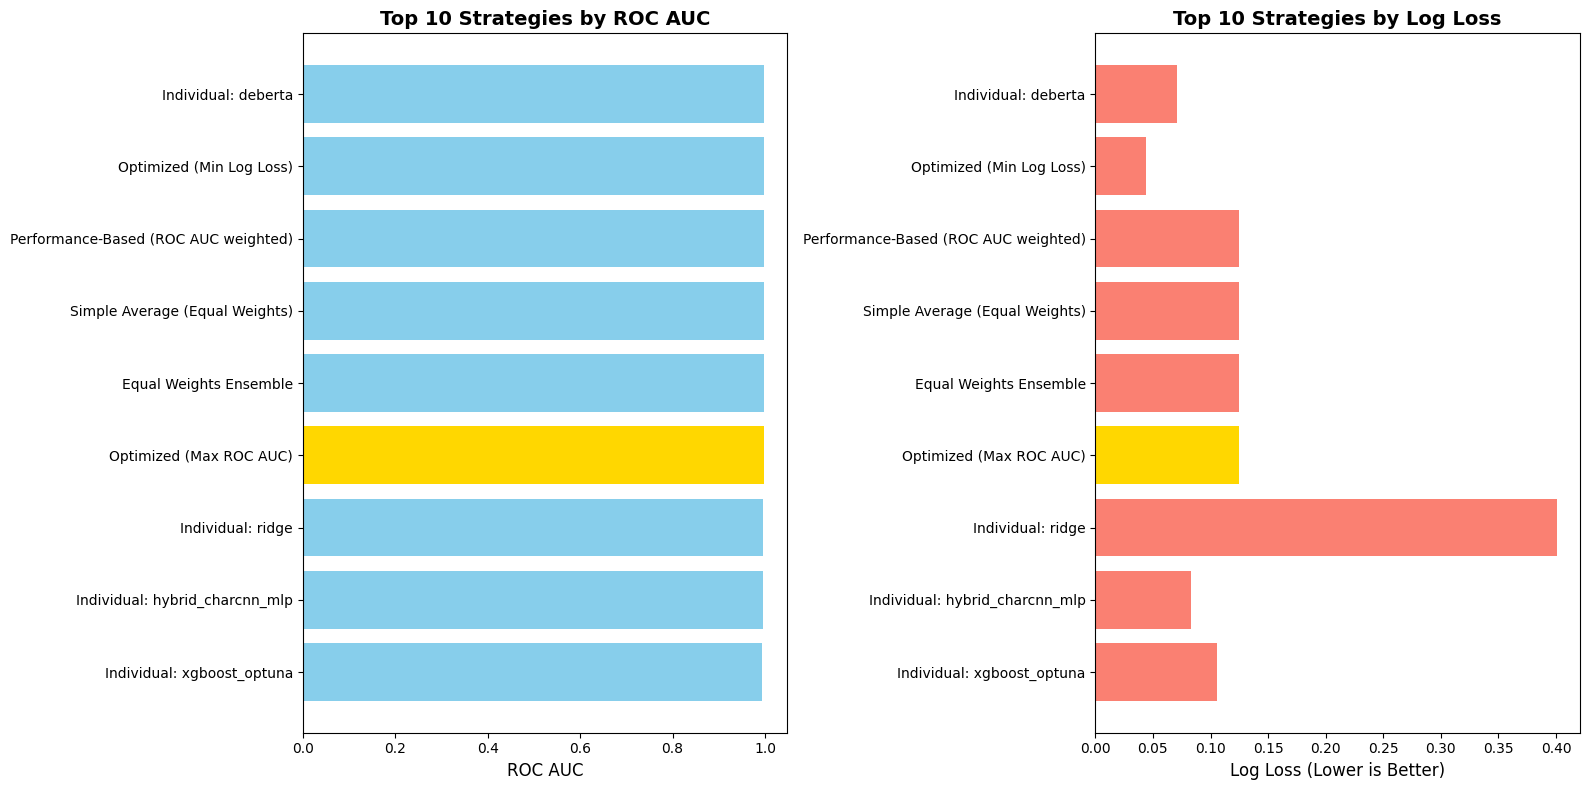


BEST STRATEGY: Individual: deberta
ROC AUC:   0.998682
Log Loss:  0.071151
F1 Score:  0.978297
Accuracy:  0.984568


In [15]:
# Visualize ensemble comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Top strategies only (for clarity)
top_strategies = ensemble_df.head(10)

# ROC AUC comparison
axes[0].barh(range(len(top_strategies)), top_strategies['ROC AUC'], 
             color=['gold' if '(Max ROC AUC)' in s else 'skyblue' for s in top_strategies['Strategy']])
axes[0].set_yticks(range(len(top_strategies)))
axes[0].set_yticklabels(top_strategies['Strategy'], fontsize=10)
axes[0].set_xlabel('ROC AUC', fontsize=12)
axes[0].set_title('Top 10 Strategies by ROC AUC', fontsize=14, fontweight='bold')
axes[0].invert_yaxis()

# Log Loss comparison (lower is better)
axes[1].barh(range(len(top_strategies)), top_strategies['Log Loss'],
             color=['gold' if '(Max ROC AUC)' in s else 'salmon' for s in top_strategies['Strategy']])
axes[1].set_yticks(range(len(top_strategies)))
axes[1].set_yticklabels(top_strategies['Strategy'], fontsize=10)
axes[1].set_xlabel('Log Loss (Lower is Better)', fontsize=12)
axes[1].set_title('Top 10 Strategies by Log Loss', fontsize=14, fontweight='bold')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

# Print best strategy
best_strategy = ensemble_df.iloc[0]
print(f"\n{'='*80}")
print(f"BEST STRATEGY: {best_strategy['Strategy']}")
print(f"{'='*80}")
print(f"ROC AUC:   {best_strategy['ROC AUC']:.6f}")
print(f"Log Loss:  {best_strategy['Log Loss']:.6f}")
print(f"F1 Score:  {best_strategy['F1 Score']:.6f}")
print(f"Accuracy:  {best_strategy['Accuracy']:.6f}")
print(f"{'='*80}")

## Save All Ensemble Configurations and Submissions

In [ ]:
# Define submission file paths
submission_files = {
    'hybrid_charcnn_mlp': 'experiments/exp_8_hybrid_charcnn_mlp/exp_8_hybrid_charcnn_mlp_submission.csv',
    'xgboost_optuna': 'experiments/exp_4_all_xgboost/exp_4_all_xgboost_submission_optuna.csv',
    'ridge': 'experiments/exp_2_tfidf_ridge/exp_2_tfidf_ridge_submission.csv',
    'deberta': 'experiments/exp_12_deberta/exp_12_deberta_submission.csv'
}

# Load all submissions
print("Loading submission files...")
submissions = {}
for model, path in submission_files.items():
    submissions[model] = pd.read_csv(path)
    print(f"  ✓ {model}")

# Create output directory
output_base_dir = 'experiments/exp_10b_weighted_ensemble'
os.makedirs(output_base_dir, exist_ok=True)

# Save each ensemble strategy
print("\n" + "="*80)
print("GENERATING SUBMISSIONS FOR ALL STRATEGIES")
print("="*80)

saved_submissions = []

for strategy_key, strategy_info in ensemble_strategies.items():
    strategy_name = strategy_info['strategy_name']
    weights_dict = strategy_info['weights']
    
    # Convert weights dict to array in correct order
    weights_array = np.array([weights_dict[col] for col in model_columns])
    
    # Create weighted ensemble submission
    ensemble_submission = submissions[model_columns[0]][['id']].copy()
    ensemble_submission['probability'] = sum(
        weights_array[i] * submissions[model]['probability'].values 
        for i, model in enumerate(model_columns)
    )
    
    # Create safe filename
    safe_filename = strategy_key.replace(' ', '_').replace('(', '').replace(')', '').replace(':', '')
    submission_path = f'{output_base_dir}/{safe_filename}_submission.csv'
    
    # Save submission
    ensemble_submission.to_csv(submission_path, index=False)
    
    # Save configuration
    config = {
        'experiment_name': safe_filename,
        'strategy': strategy_name,
        'timestamp': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
        'model_weights': weights_dict,
        'oof_metrics': strategy_info['metrics'],
        'submission_files': submission_files
    }
    
    config_path = f'{output_base_dir}/{safe_filename}_config.json'
    with open(config_path, 'w') as f:
        json.dump(config, f, indent=2)
    
    saved_submissions.append({
        'Strategy': strategy_name,
        'File': submission_path,
        'Mean Prob': ensemble_submission['probability'].mean(),
        'ROC AUC (OOF)': strategy_info['metrics']['ROC AUC']
    })
    
    print(f"✓ {strategy_name}")
    print(f"  Submission: {submission_path}")
    print(f"  Config: {config_path}")
    print(f"  Mean probability: {ensemble_submission['probability'].mean():.4f}")
    print()

# Create summary of all saved submissions
submissions_summary_df = pd.DataFrame(saved_submissions)
submissions_summary_df = submissions_summary_df.sort_values('ROC AUC (OOF)', ascending=False)

summary_path = f'{output_base_dir}/submissions_summary.csv'
submissions_summary_df.to_csv(summary_path, index=False)

print("="*80)
print(f"✓ All submissions saved to: {output_base_dir}/")
print(f"✓ Summary saved to: {summary_path}")
print(f"✓ Total strategies saved: {len(saved_submissions)}")
print("="*80)

submissions_summary_df

Best configuration saved to 'best_ensemble_config.json'

Configuration summary:
{
  "hybrid_charcnn_mlp": 0.25,
  "xgboost_optuna": 0.25,
  "ridge": 0.25,
  "deberta": 0.25
}


## Summary Statistics

In [ ]:
print("="*80)
print("FINAL SUMMARY - MODEL TRACKING METRICS")
print("="*80)

print("\nIndividual Model Performance:")
print("-" * 80)
for _, row in comparison_df.iterrows():
    print(f"{row['model']:25s} | ROC AUC: {row['roc_auc']:.6f} | Log Loss: {row['log_loss']:.6f}")

print("\n\nEnsemble Strategies Performance:")
print("-" * 80)
for _, row in ensemble_df.head(10).iterrows():
    print(f"{row['Strategy']:40s} | ROC AUC: {row['ROC AUC']:.6f} | Log Loss: {row['Log Loss']:.6f}")

print("\n\nBest Strategy:")
print("-" * 80)
best = ensemble_df.iloc[0]
print(f"Strategy: {best['Strategy']}")
print(f"ROC AUC:  {best['ROC AUC']:.6f}")
print(f"Log Loss: {best['Log Loss']:.6f}")
print(f"F1 Score: {best['F1 Score']:.6f}")
print(f"Accuracy: {best['Accuracy']:.6f}")

print("\n\nAll Submission Files Saved:")
print("-" * 80)
for _, row in submissions_summary_df.iterrows():
    print(f"{row['Strategy']:40s}")
    print(f"  File: {row['File']}")
    print(f"  Mean Prob: {row['Mean Prob']:.4f} | OOF ROC AUC: {row['ROC AUC (OOF)']:.6f}")
    print()

print("="*80)

FINAL SUMMARY - MODEL TRACKING METRICS

Individual Model Performance:
--------------------------------------------------------------------------------
deberta                   | ROC AUC: 0.998682 | Log Loss: 0.071151
ridge                     | ROC AUC: 0.996512 | Log Loss: 0.400754
hybrid_charcnn_mlp        | ROC AUC: 0.995448 | Log Loss: 0.082627
xgboost_optuna            | ROC AUC: 0.992743 | Log Loss: 0.105575


Ensemble Strategies:
--------------------------------------------------------------------------------
Simple Average            | ROC AUC: 0.998393 | Log Loss: 0.124975
Equal Weights             | ROC AUC: 0.998393 | Log Loss: 0.124975
Performance-Based         | ROC AUC: 0.998394 | Log Loss: 0.124988


Optimized Strategies:
--------------------------------------------------------------------------------
Optimized (ROC AUC)       | ROC AUC: 0.998393 | Log Loss: 0.124975
Optimized (Log Loss)      | ROC AUC: 0.998455 | Log Loss: 0.044407


Best Model/Strategy:
--------------